In [1]:
datadir = './'

In [2]:
from glob import glob

In [3]:
import rasterio
import numpy as np

In [4]:
from prominence import getProminence
from matplotlib import patches, patheffects
import matplotlib
from scipy.ndimage import gaussian_filter

In [5]:
import matplotlib.pyplot as plt

In [6]:
from scipy.ndimage.filters import gaussian_filter
import matplotlib.patheffects as pe

/tmp/ipykernel_3269/1876008511.py:1: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import gaussian_filter


In [7]:
files = glob(f"{datadir}/*.tif")

In [8]:
def find_nearest_ix(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

In [9]:
from math import floor
def get_file(lat, lon, prepend):
    lat = floor(lat)
    lon = floor(lon)
    return f"{prepend}/n{lat:.0f}_w{abs(lon):03.0f}_1arc_v3.tif"

datasets = {}

def open_data(lat, lon, prepend):
    try:
        dataset = datasets[f"{floor(lat):.0f}_w{floor(abs(lon)):03.0f}"]
    except KeyError:
        
        dataset = rasterio.open(get_file(lat, lon, prepend))
        datasets[f"{floor(lat):.0f}_w{floor(abs(lon)):03.0f}"] = dataset
    lons = np.linspace(dataset.bounds.left, dataset.bounds.right, dataset.shape[1])
    lats = np.linspace(dataset.bounds.top, dataset.bounds.bottom, dataset.shape[0])
    return lats, lons, dataset.read(1)

def get_nearest(lat, lon, prepend="/home/daniel/bda/Bulk Order 20200727_052331/SRTM 1 Arc-Second Global"):
    lats, lons, data = open_data(lat, lon, prepend)         
    near_lat = find_nearest_ix(lats, lat)
    near_lon = find_nearest_ix(lons, lon)
    return data[near_lat, near_lon]

In [10]:
# Ben Nevis
lat, lon = 56.79685, -5.003508

In [11]:
# Cairn Gorm
late, lon = 57.116137, -3.644717

In [12]:
# Earl's Seat
lat, lon = 56.0257, -4.2964

In [13]:
# Hart Fell
lat, lon = 55.40806, -3.40142

In [14]:
late, lon = 55.393461,-3.3698099

In [15]:
import gpxpy
import gpxpy.gpx

# Parsing an existing file:
# -------------------------



In [16]:
mlats = gpx.get_bounds().min_latitude, gpx.get_bounds().max_latitude
mlons = gpx.get_bounds().min_longitude, gpx.get_bounds().max_longitude

NameError: name 'gpx' is not defined

In [ ]:
#center = (lat,lon)
height_route = mlons[1] - mlons[0] #  0.075
width_route = mlats[1] - mlats[0]#  0.075

center = mlats[0] + width_route/2, mlons[0] + height_route/2

#height, width = 0.1, 0.1
height = 1.35 * max((height_route, width_route))
width = height

In [ ]:
lats, lons, data = open_data(lat, lon, prepend=datadir)

In [ ]:
gpx.smooth(True, True)

In [17]:
import pandas

In [18]:
hill_database.query("M==1 and `Topo Section`=='N01:Crianlarich Hills to Loch Arklet'")

NameError: name 'hill_database' is not defined

In [22]:
cache = {}

In [23]:
def plot_countours(interval=5, smooth=4, center=None, route=None, labels=True, hills=None, height = 0.1, width=0.1, 
                   points=True,
                   figsize=(4,4),
                   circle_mask=True,
                   refresh=False,
                   zoom=1.35,
                   cats=["M", "MT", "xMT", "C", "D", "DT"],
                   density=1500):
    f, ax = plt.subplots(1,1, dpi=300, figsize=figsize)
    
    if route:
        with open(route, 'r') as gpx_file:

            gpx = gpxpy.parse(gpx_file)
        lats_route = [i.latitude for i in gpx.tracks[0].segments[0].points]
        lons_route = [i.longitude for i in gpx.tracks[0].segments[0].points]
        
        mlats = gpx.get_bounds().min_latitude, gpx.get_bounds().max_latitude
        mlons = gpx.get_bounds().min_longitude, gpx.get_bounds().max_longitude
        
        #center = (lat,lon)
        height_route = mlons[1] - mlons[0] #  0.075
        width_route = mlats[1] - mlats[0]#  0.075

        center = mlats[0] + width_route/2, mlons[0] + height_route/2

        #height, width = 0.1, 0.1
        height = 1.35 * max((height_route, width_route))
        width = height
        
    elif hills:
        query = hills
        hill_database = pandas.read_csv("../hills/data/DoBIH_v17_3.csv")
        hills = hill_database.query(hills)
        mlats = hills.Latitude.min(), hills.Latitude.max()
        mlons = hills.Longitude.min(), hills.Longitude.max()
        height_set = max((mlons[1] - mlons[0], height))
        width_set = max((mlats[1] - mlats[0], width))
        
        height = zoom * max((height_set, width_set))
        width = height
        center = mlats[0] + (mlats[1] - mlats[0])/2, mlons[0] + (mlons[1] - mlons[0])/2

    # Get the data
    nx, ny = int(density*height), int(density*width)

    data = np.zeros((nx, ny))

    lons = np.linspace(center[0]-width/2, center[0]+width/2, ny)
    lats = np.linspace(center[1]-height/2, center[1]+height/2, nx)

    aa, bb = np.meshgrid(lons, lats)
    
    if not query in cache or refresh:
        for i in range(len(lons)):
            for j in range(len(lats)):
                data[i, j] = get_nearest(aa[i, j], bb[i, j], prepend=datadir)
        cache[query] = data
    else:
        data = cache[query]
    # Draw the contours
    graham = int(2000 / 3.28084 /10) * 10
    corbett = int(2500 / 3.28084 / 10) * 10
    munro = int(3000 / 3.28084 / 10) * 10
    
    img = gaussian_filter(data.T, sigma=smooth)

    if circle_mask:
        rad = 0.9*(width/2)

        xm, ym = lats[int(len(lats)/2)], lons[int(len(lons)/2)]

        aa, bb = np.meshgrid(lons, lats)
        mask = (bb - xm) ** 2 + (aa - ym) ** 2 > rad ** 2

        img_ma = np.ma.array(img, mask=mask)
        
    else:
        img_ma = img

    a = ax.contour(lats, lons, img_ma, levels=np.arange(0,graham, interval), linewidths=0.05, colors='#333', antialiased=True, interpolation='antialiased')
    b = ax.contour(lats, lons, img_ma, levels=np.arange(graham,corbett, interval), linewidths=0.1, colors='#333', antialiased=True, interpolation='antialiased')
    c = ax.contour(lats, lons, img_ma, levels=np.arange(corbett,munro, interval), linewidths=0.15, colors='#333', antialiased=True, interpolation='antialiased')
    d = ax.contour(lats, lons, img_ma, levels=np.arange(munro,1400, interval), linewidths=0.2, colors='#333', antialiased=True, interpolation='antialiased')
    ax.grid(None)
    ax.set_xticks([])
    ax.set_yticks([])

    if route:
        ax.plot(lons_route, lats_route)

    ax.axis('off')
    ax.set_aspect('equal')

    for cat in cats[::-1]:
        hill_points = hill_database[hill_database[cat]==1][['Latitude','Longitude', 'Name']].values
        if circle_mask:
            mask = (hill_points[:,1] - xm) ** 2 + (hill_points[:,0] - ym) ** 2 > rad ** 2
        else:
            mask = np.ones(len(hill_points))
        if points:
            ax.plot(np.ma.array(hill_points[:,1], mask=mask), np.ma.array(hill_points[:,0], mask=mask), '^')
        
        if labels:
            for i in range(len(hill_points)):
                if points: 
                    ha = "right"
                else:
                    ha="center"
                ax.text(np.ma.array(hill_points[:,1], mask=mask)[i]+ width*.02, 
                        np.ma.array(hill_points[:,0], mask=mask)[i]+height*0.03, 
                        s=np.ma.array(hill_points[:,2], mask=mask)[i], horizontalalignment=ha,
                       fontdict={"family": "Georgia"},
                        path_effects=[patheffects.withStroke(linewidth=3, alpha=0.85,
                                                                foreground="w")],
                       )

    ax.set_xlim([lats.min(), lats.max()])
    ax.set_ylim([lons.min(), lons.max()])  
    rad = (width/2)
    if circle_mask:
        ax.add_patch(plt.Circle((xm, ym), rad*0.98, color='black'))
        ax.add_patch(plt.Circle((xm, ym), rad*0.85, color='white'))

    f.tight_layout()
    return f

/tmp/ipykernel_3269/1776872824.py:33: DtypeWarning: Columns (3,25) have mixed types. Specify dtype option on import or set low_memory=False.
  hill_database = pandas.read_csv("../hills/data/DoBIH_v17_3.csv")
/tmp/ipykernel_3269/1776872824.py:81: UserWarning: The following kwargs were not used by contour: 'interpolation'
  a = ax.contour(lats, lons, img_ma, levels=np.arange(0,graham, interval), linewidths=0.05, colors='#333', antialiased=True, interpolation='antialiased')
/tmp/ipykernel_3269/1776872824.py:82: UserWarning: The following kwargs were not used by contour: 'interpolation'
  b = ax.contour(lats, lons, img_ma, levels=np.arange(graham,corbett, interval), linewidths=0.1, colors='#333', antialiased=True, interpolation='antialiased')
/tmp/ipykernel_3269/1776872824.py:83: UserWarning: The following kwargs were not used by contour: 'interpolation'
  c = ax.contour(lats, lons, img_ma, levels=np.arange(corbett,munro, interval), linewidths=0.15, colors='#333', antialiased=True, interpo

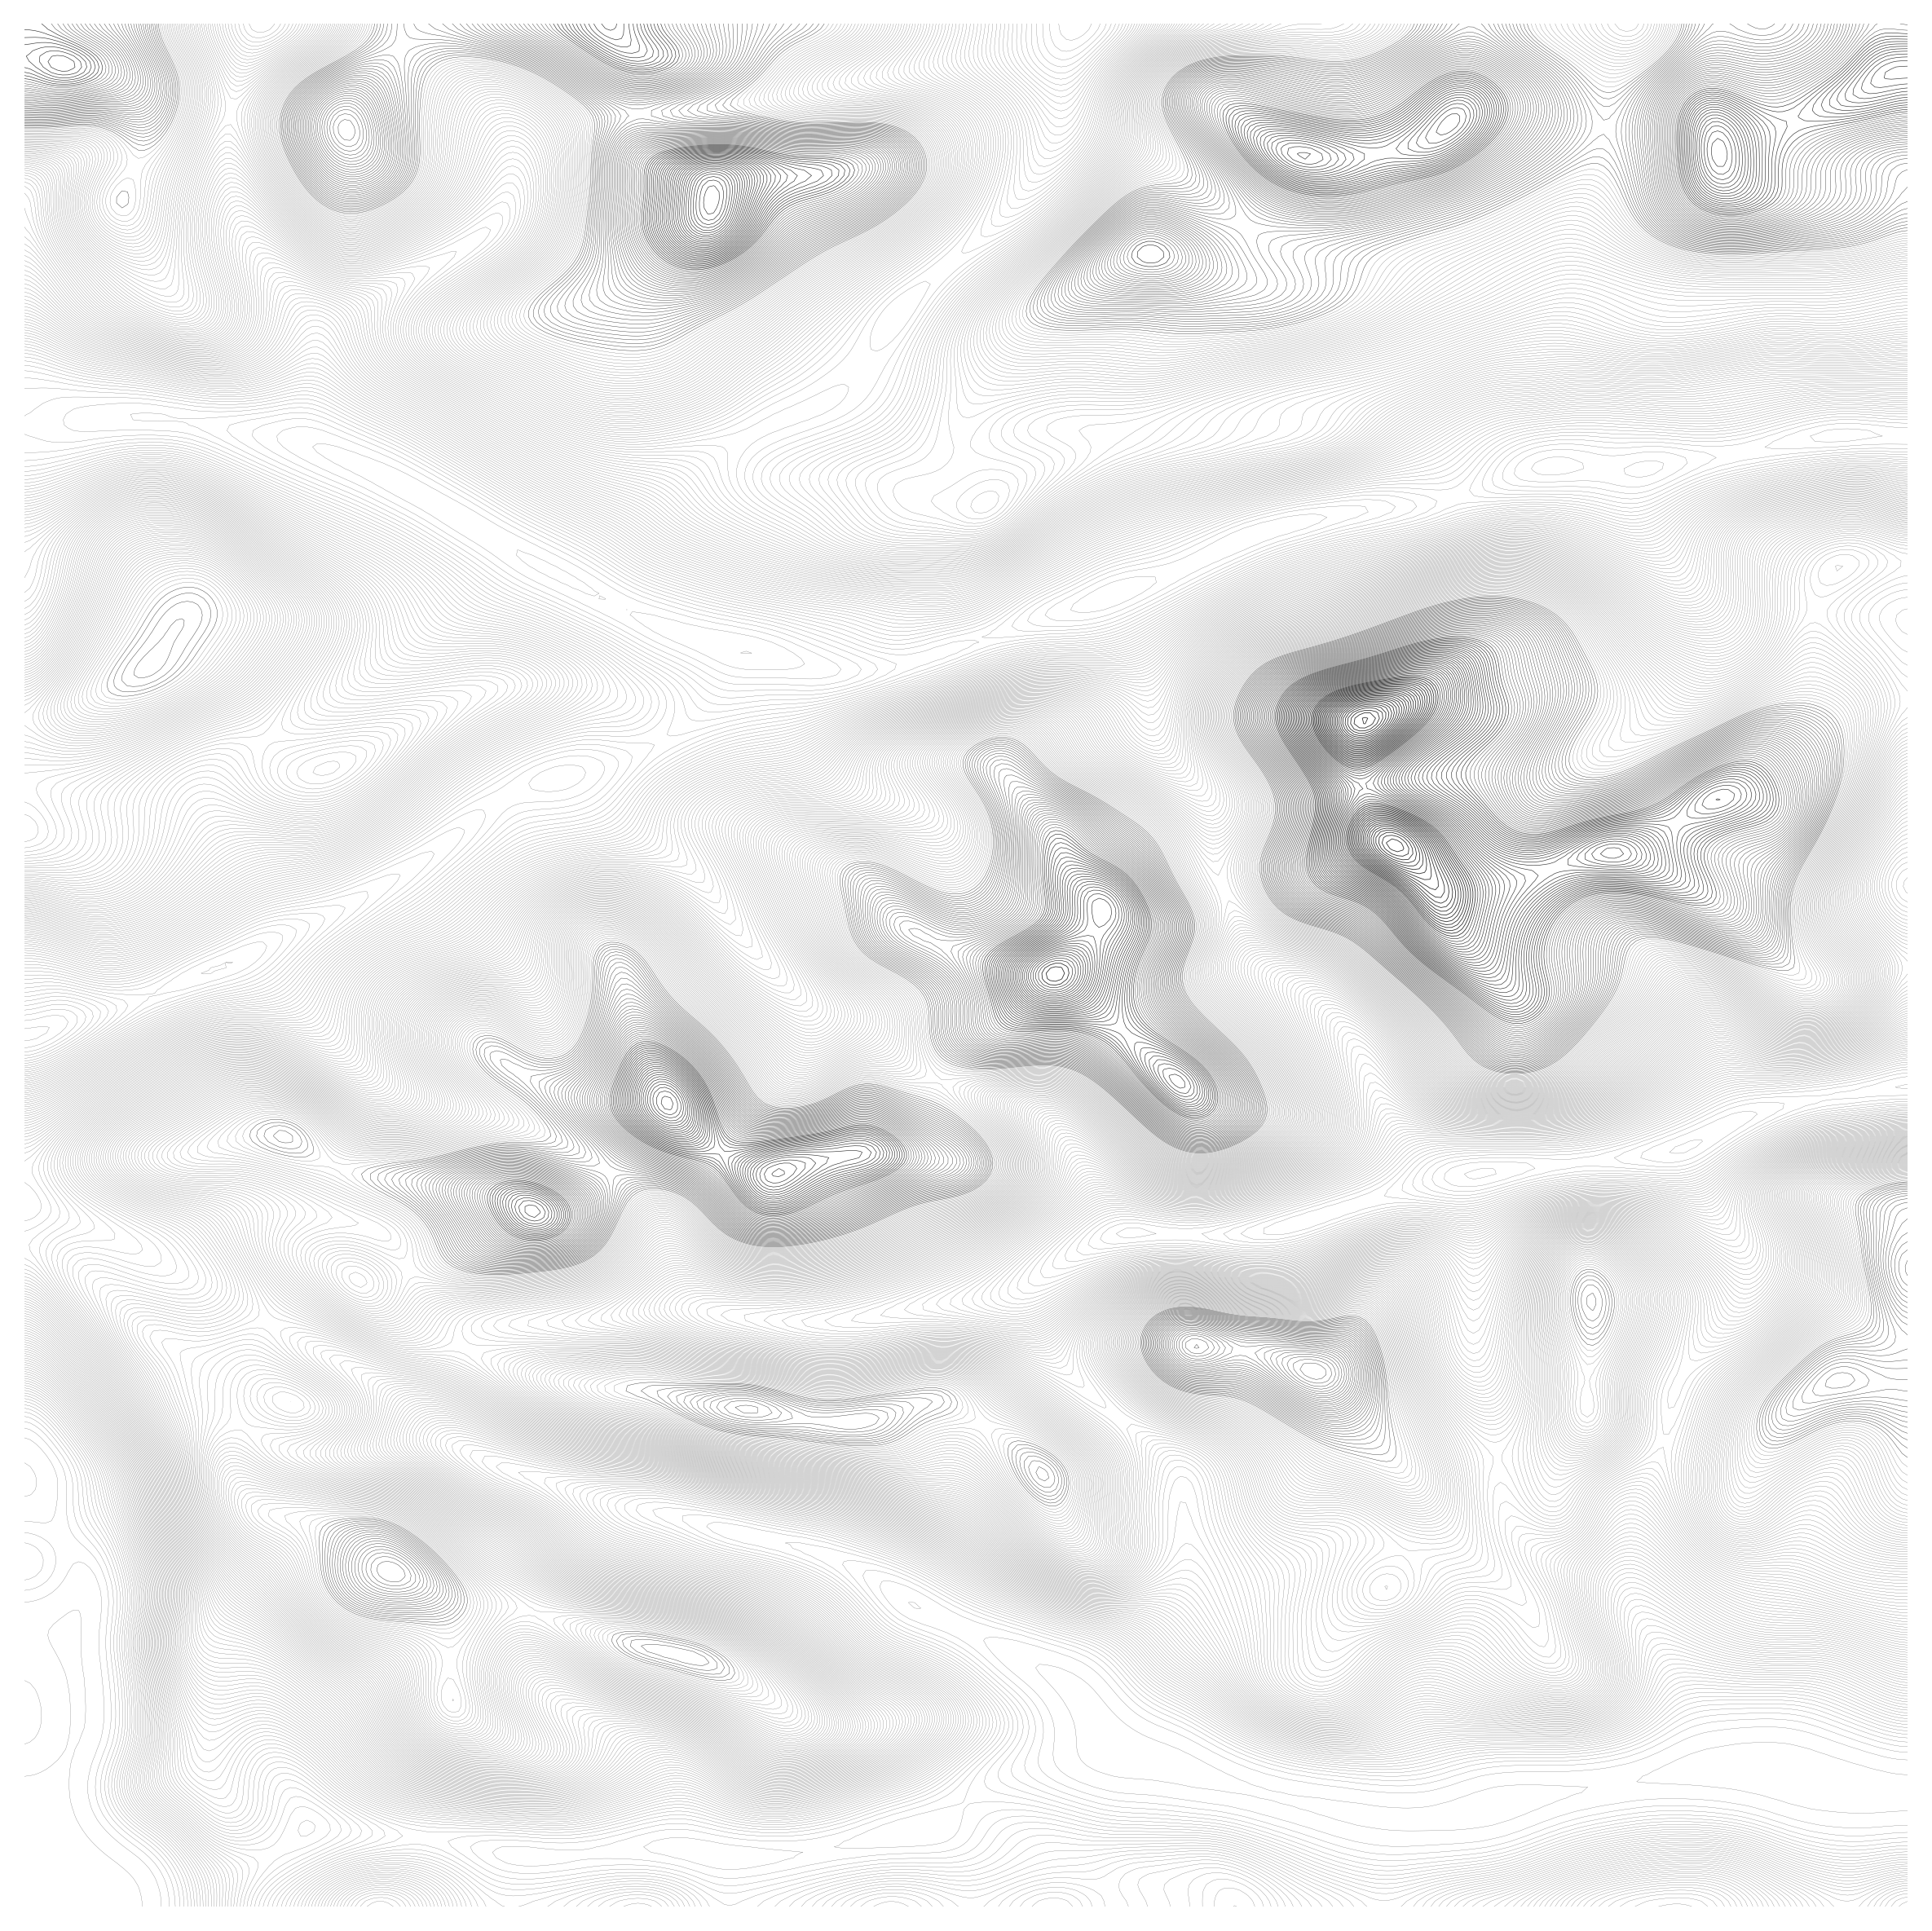

In [26]:
no = 2
f= plot_countours(
    hills = "M==1 and `Topo Section`=='N01:Crianlarich Hills to Loch Arklet'",
    labels=True,
    points=False,
    #cats=["M"],
    density=1500,
    width=0.075,
    height=0.075,
    circle_mask = False,
    figsize=(8,8),
    zoom=2.2,
    refresh=True,
    #smooth=3,
    #route="The_Hart_Fell_Round_.gpx", labels=False)
)

In [27]:
f.savefig("crianlarich.svg")

In [ ]:
hill_database['Topo Section'].unique()

In [ ]:
no = 2
f= plot_countours(
    hills = "`Topo Section`=='M07:Loch Long to Loch Lomond' and G==1",
    labels=True,
    points=False,
    #cats=["M"],
    density=1500,
    width=0.075,
    height=0.075,
    circle_mask = False,
    figsize=(8,8),
    zoom=1.9,
    refresh=True,
    #smooth=3,
    #route="The_Hart_Fell_Round_.gpx", labels=False)
)

In [ ]:
no = 2
f= plot_countours(
    hills = "`Topo Section`=='I02:The Mamores' and M == 1",
    labels=True,
    points=False,
    #cats=["M"],
    density=1500,
    width=0.075,
    height=0.075,
    circle_mask = False,
    figsize=(8,8),
    zoom=1.2,
    refresh=True,
    #smooth=3,
    #route="The_Hart_Fell_Round_.gpx", labels=False)
)

In [ ]:
hill_database.query("`Topo Section`=='M07:Loch Long to Loch Lomond' and G==1")

In [ ]:
hill_database.query("Name=='Doune Hill'")

In [ ]:
no = 2
f= plot_countours(
    hills = "M==1 and `Topo Section`=='N01:Crianlarich Hills to Loch Arklet'",
    labels=True,
    points=False,
    #cats=["M"],
    density=1500,
    width=0.075,
    height=0.075,
    circle_mask = False,
    figsize=(8,8),
    zoom=1.9,
    refresh=True,
    #smooth=3,
    #route="The_Hart_Fell_Round_.gpx", labels=False)
)

In [ ]:
hills = hill_database.query('M==1')
for hill in hills.iterrows():
    no = hill[1].Number
    name = hill[1].Name.split(" [")[0].replace("'","").replace(" ", "-")
    f= plot_countours(
        hills = f'Number == {no}',
        labels=False,
        points=False,
        #cats=["M"],
        density=1500,
        width=0.075,
        height=0.075,
        #smooth=3,
        #route="The_Hart_Fell_Round_.gpx", labels=False)
    )
    f.savefig(f"munros/{name}.png")
    f.savefig(f"munros/{name}.svg")
    plt.close()

In [ ]:
hills = hill_database.query('(D==1) or (DT==1)')
for hill in hills.iterrows():
    no = hill[1].Number
    name = hill[1].Name.split(" [")[0].replace("'","").replace(" ", "-")
    f= plot_countours(
        hills = f'Number == {no}',
        labels=False,
        points=False,
        #cats=["M"],
        density=1500,
        width=0.075,
        height=0.075,
        #smooth=3,
        #route="The_Hart_Fell_Round_.gpx", labels=False)
    )
    f.savefig(f"donalds/{name}.png")
    f.savefig(f"donalds/{name}.svg")
    plt.close()

In [ ]:
hills = hill_database.query('(C==1)')
for hill in hills.iterrows():
    no = hill[1].Number
    name = hill[1].Name.split(" [")[0].replace("'","").replace(" ", "-")
    f= plot_countours(
        hills = f'Number == {no}',
        labels=False,
        points=False,
        #cats=["M"],
        density=1500,
        width=0.075,
        height=0.075,
        #smooth=3,
        #route="The_Hart_Fell_Round_.gpx", labels=False)
    )
    f.savefig(f"corbetts/{name}.png")
    f.savefig(f"corbetts/{name}.svg")
    plt.close()

In [ ]:
hills = hill_database.query('(G==1)')
for hill in hills.iterrows():
    no = hill[1].Number
    name = hill[1].Name.split(" [")[0].replace("'","").replace(" ", "-")
    f= plot_countours(
        hills = f'Number == {no}',
        labels=False,
        points=False,
        #cats=["M"],
        density=1500,
        width=0.075,
        height=0.075,
        #smooth=3,
        #route="The_Hart_Fell_Round_.gpx", labels=False)
    )
    f.savefig(f"grahams/{name}.png")
    f.savefig(f"grahams/{name}.svg")
    plt.close()